In [1]:
import pandas as pd

In [2]:
# Results table: one row per driver per race.
# In this dataset \N means that driver did not finish.
res = pd.read_csv("data/results.csv", na_values=r"\N")

In [3]:
# Races table: one row per race. It contains the year of each race.
races = pd.read_csv("data/races.csv")

In [4]:
#SMall overwiew of datasets. 
print(res.shape)

(26759, 18)


In [5]:
print(races.shape)

(1125, 18)


In [6]:
# Join results.csv and races.csv by the common column (raceId).
# We only take raceId and year from races, because we need nothing else.
df = res.merge(races[["raceId", "year"]], on="raceId")

# Check which seasons we have.
print("years in data:", df["year"].min(), "-", df["year"].max())

years in data: 1950 - 2024


In [7]:
import numpy as np
# Keep only races from 2014 onward.
# Also we drop grid == 0: in this dataset 0 means a pit-lane start, which is not a normal grid position and would distort the line.
# .copy() makes an independent table
df = df[(df["year"] >= 2014) & (df["grid"] > 0)].copy()

# New column "era": "ground_effect" if the year is 2022 or later,
# otherwise "hybrid". This is what we compare.
df["era"] = np.where(df["year"] >= 2022, "ground_effect", "hybrid")

# New column "podium": 1 if the driver finished in the top 3, else 0.
# positionOrder is always filled in, even for drivers who did not finish,  so a DNF correctly counts as "no podium" (0).
df["podium"] = (df["positionOrder"] <= 3).astype(int)

# How many rows per era? Shows the size difference between the two.
print(df["era"].value_counts())

era
hybrid           3228
ground_effect    1319
Name: count, dtype: int64


In [8]:
import statsmodels.formula.api as smf

# The linear model only makes sense for drivers who FINISHED,
# because a DNF has no finishing position to predict.
# "position" is empty (NaN) for DNFs, so I remove those rows.
fin = df.dropna(subset=["position"])

# Loop over each era separately. groupby splits the table into two groups.
for era, d in fin.groupby("era"):
    # "position ~ grid" means: predict finishing position from grid position.
    # running ols
    lin = smf.ols("position ~ grid", data=d).fit()

    # slope = finishing places lost per grid place further back.
    # R2 = share of the variation in finishing position explained by the grid position in the start.
    print(era,
          "| slope:", round(lin.params["grid"], 2),
          "| R2:", round(lin.rsquared, 2))

ground_effect | slope: 0.67 | R2: 0.53
hybrid | slope: 0.64 | R2: 0.57


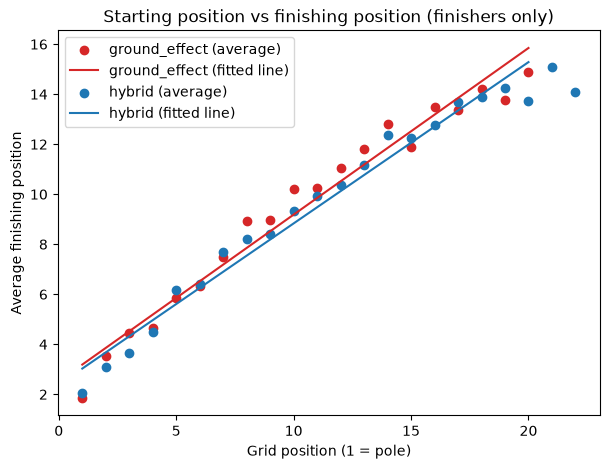

In [9]:
#Let's plot it
import matplotlib.pyplot as plt

# One colour per era, so the dots and the line of an era match.
colors = {"hybrid": "tab:blue", "ground_effect": "tab:red"}

fig, ax = plt.subplots(figsize=(7, 5))


for era, d in fin.groupby("era"):
    # Average finishing position for each grid position (one dot per grid slot).
    # Plotting 4000+ raw points would be an unreadable blob, so we plot averages.
    avg = d.groupby("grid")["position"].mean()
    ax.scatter(avg.index, avg.values, color=colors[era], label=era + " (average)")

    # Fit the same straight line as in cell 4.
    lin = smf.ols("position ~ grid", data=d).fit()
    # x values for the line: grid positions 1 to 20.
    x = np.arange(1, 21)

    y = lin.params["Intercept"] + lin.params["grid"] * x
    ax.plot(x, y, color=colors[era], label=era + " (fitted line)")

ax.set_xlabel("Grid position (1 = pole)")
ax.set_ylabel("Average finishing position")
ax.set_title("Starting position vs finishing position (finishers only)")
ax.legend()

fig.savefig("figures/fig1_linear.pdf")
fig.savefig("docs/fig1_linear.png")

plt.show()

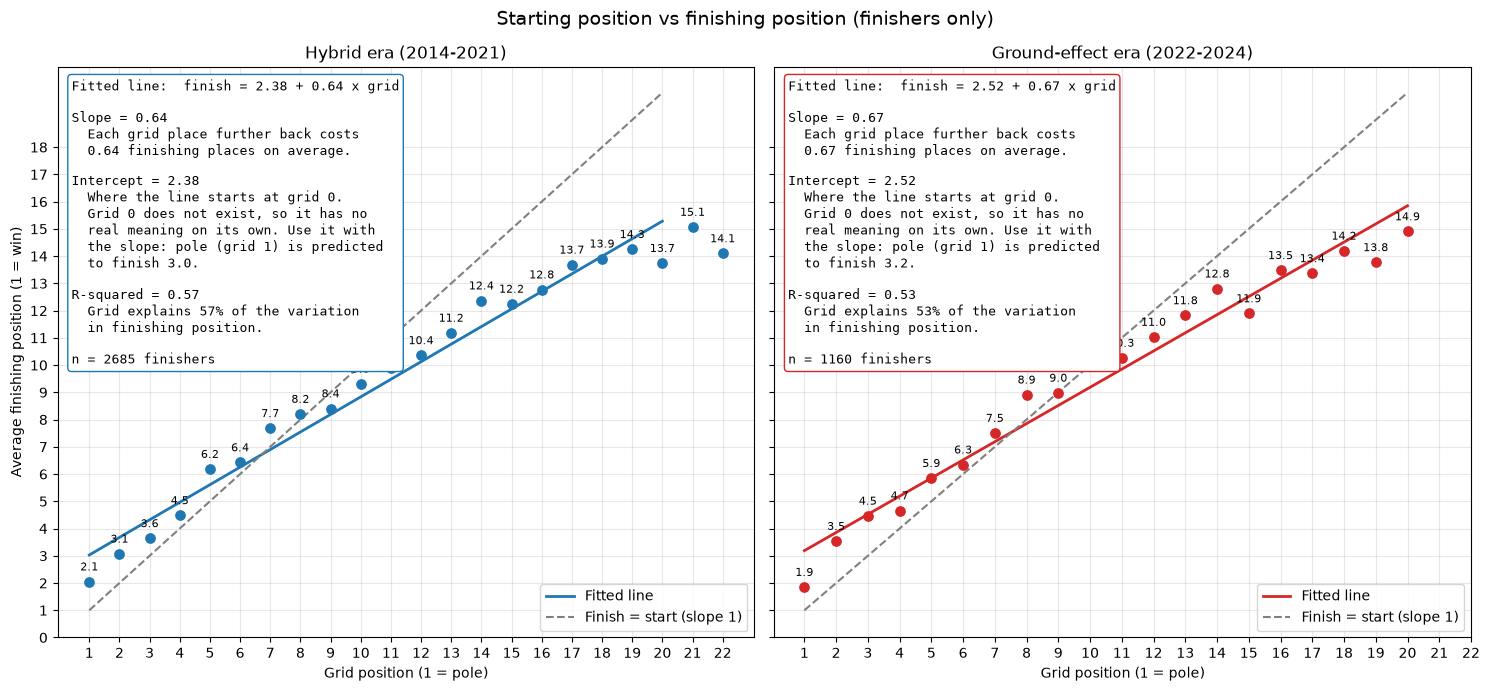

In [10]:
import matplotlib.pyplot as plt

colors = {"hybrid": "tab:blue", "ground_effect": "tab:red"}

names = {"hybrid": "Hybrid era (2014-2021)",
         "ground_effect": "Ground-effect era (2022-2024)"}

fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)

# Loop over the two eras. zip pairs each era with its own panel (ax).
for ax, era in zip(axes, ["hybrid", "ground_effect"]):

    # Take only this era's finishers.
    d = fin[fin["era"] == era]

    # Fit the straight line again: position = intercept + slope * grid.
    lin = smf.ols("position ~ grid", data=d).fit()

    a = lin.params["Intercept"]   # intercept: where the line starts
    b = lin.params["grid"]        # slope: places lost per grid place
    r2 = lin.rsquared             # share of variation explained
    n = int(lin.nobs)             # number of driver-race rows used

    # Average finishing position for each grid slot (one dot per slot).
    avg = d.groupby("grid")["position"].mean()

    ax.scatter(avg.index, avg.values, color=colors[era], s=45, zorder=3)

    for x_val, y_val in avg.items():
        ax.annotate(f"{y_val:.1f}", (x_val, y_val),
                    textcoords="offset points", xytext=(0, 8),
                    ha="center", fontsize=8)

    x = np.arange(1, 21)
    ax.plot(x, a + b * x, color=colors[era], linewidth=2, label="Fitted line")

    # Dashed grey reference line: "if you finished where you started".
    # If the grid decided everything, the dots would sit on this line.
    ax.plot(x, x, color="grey", linestyle="--", label="Finish = start (slope 1)")

    # Where the line predicts a pole-sitter finishes: intercept + slope * 1.
    pole_pred = a + b * 1

    text = (
        f"Fitted line:  finish = {a:.2f} + {b:.2f} x grid\n\n"
        f"Slope = {b:.2f}\n"
        f"  Each grid place further back costs\n"
        f"  {b:.2f} finishing places on average.\n\n"
        f"Intercept = {a:.2f}\n"
        f"  Where the line starts at grid 0.\n"
        f"  Grid 0 does not exist, so it has no\n"
        f"  real meaning on its own. Use it with\n"
        f"  the slope: pole (grid 1) is predicted\n"
        f"  to finish {pole_pred:.1f}.\n\n"
        f"R-squared = {r2:.2f}\n"
        f"  Grid explains {r2*100:.0f}% of the variation\n"
        f"  in finishing position.\n\n"
        f"n = {n} finishers"
    )

    ax.text(0.02, 0.98, text, transform=ax.transAxes, va="top",
            fontsize=9, family="monospace",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor=colors[era]))

    ax.set_title(names[era])
    ax.set_xlabel("Grid position (1 = pole)")

    ax.set_xticks(range(1, 23))
    ax.set_yticks(range(0, 19))
    ax.grid(alpha=0.3)

    ax.legend(loc="lower right")


axes[0].set_ylabel("Average finishing position (1 = win)")

fig.suptitle("Starting position vs finishing position (finishers only)", fontsize=14)

fig.tight_layout()

fig.savefig("figures/fig1_linear.pdf")
fig.savefig("docs/fig1_linear.png", dpi=150)

plt.show()